In [1]:
import numpy as np
import ot_utils
import comparison_utils
from tqdm import tqdm
import math
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

In [2]:
def pairwise_distance_matrix(rel_rep, i_ut=None, j_ut=None):
    n = rel_rep.shape[0]
    if i_ut is None or j_ut is None:
        i_ut, j_ut = np.triu_indices(n, k=1)

    dmat = np.zeros((n, n), dtype=float)
    for i, j in zip(i_ut, j_ut):
        d = comparison_utils.eud_dist(rel_rep[i], rel_rep[j])
        dmat[i, j] = d
        dmat[j, i] = d

    return dmat


def kNN_with_distance_matrix(
    l_matrix,
    labels,
    train_number,
    val_number,
    test_number,
    neighbor_list,
    AUC_list=False,
):
    """
    Inputs:

        l_matrix:          The distance matrix(2D np array) of the two types of jets. Shape:(njets, njets)
                          (NOTE: This matrix must be symmetric and tracless for it to be a meaningful OT distance matrix)

        labels:           An array of labels for which type of particle each row/column belongs to. Shape(njets,)

        train_number:     The number of jets used for training the kNN model, set to be the first "train_number" of rows/cols

        val_number:       The number of jets used for the validation process(determining the best number of neighbors), set to be the "val_number" of rows/cols right after the training rows/cols

        test_number:      The number of jets used for the testing process, set to be the "test_number" of rows/cols right after the validation rows/cols

        neighbor_list:   The list of neighbors wanted to be used for the kNN classification

        AUC_list:         Default is False. When set to True, return the whole list of AUCs during the validation process

    Outputs:

        best_auc:         The AUC computed using the best-k-neighbor returned by the validation process.

        auc_list:         The entire list of AUC computed during the validation process. Only returned if AUC_list is set to be True

    """

    # Split the distance matrix and labels into training, validation and testing sets
    l_matrix_train = l_matrix[:train_number, :train_number]
    l_matrix_val_train = l_matrix[
        train_number : train_number + val_number, :train_number
    ]
    l_matrix_trainval = l_matrix[
        : train_number + val_number, : train_number + val_number
    ]
    l_matrix_test_trainval = l_matrix[
        train_number + val_number : test_number + train_number + val_number,
        : train_number + val_number,
    ]

    # Split the labels into training, validation and testing sets
    train_labels = labels[:train_number]
    val_labels = labels[train_number : train_number + val_number]
    trainval_labels = labels[: train_number + val_number]
    test_labels = labels[
        train_number + val_number : test_number + train_number + val_number
    ]

    models, pred_vals = [], []

    for neighbor in tqdm(neighbor_list, desc="Fitting Models"):
        model = KNeighborsClassifier(n_neighbors=neighbor, metric="precomputed")
        model.fit(l_matrix_train, train_labels)
        pred_val = model.predict_proba(l_matrix_val_train)[:, 1]
        models.append(model)
        pred_vals.append(pred_val)

    auc_list = []

    # Compute the AUC for each k-neighbor model
    for pred in pred_vals:
        auc = roc_auc_score(val_labels, pred)
        auc_list.append(auc)

    max_index = auc_list.index(max(auc_list))

    # Get the best k-neighbor model
    best_k_neighbor = neighbor_list[max_index]

    best_model = KNeighborsClassifier(n_neighbors=best_k_neighbor, metric="precomputed")

    # Train the best k-neighbor model
    best_model.fit(l_matrix_trainval, trainval_labels)

    # Get the prediction probabilities for the testing set
    best_pred = best_model.predict_proba(l_matrix_test_trainval)[:, 1]

    # kNN_metrics = kNN_ROC_metrics(test_labels, best_pred, Interpolate=True)

    best_auc = roc_auc_score(test_labels, best_pred)

    if AUC_list:
        return best_auc, best_k_neighbor, best_model, auc_list

    else:
        return best_auc, best_k_neighbor, best_model

In [3]:
block_files_matrix = []

for i in range(8):
    block_files_matrix.append([])
    for j in range(8):
        if j < i:
            block_files_matrix[i].append(f"ps_block_{j}_{i}")
        else:
            block_files_matrix[i].append(f"ps_block_{i}_{j}")

In [4]:
classification_aucs = np.zeros((8, 8))
best_ks = np.zeros((8, 8))

num_events_per_class = 4000

with open('project_path.txt') as f:
    local_project_path = f.read()

for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = local_project_path + f"medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = local_project_path + f"medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = local_project_path + f"medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps_w2 = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=100, seed=42
    )
    
    rel_reps_w2 *= 10
    
    self_matrix_1_file = local_project_path + f"medium_ps/ps_block_{i}_{i}.npy"
    self_matrix_2_file = local_project_path + f"medium_ps/ps_block_{j}_{j}.npy"
    off_diag_matrix_file = local_project_path + f"medium_ps/ps_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps_ps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=400, seed=42
    )
    
    rel_reps = np.concatenate((rel_reps_w2, rel_reps_ps), axis=1)

    dist_mat = pairwise_distance_matrix(rel_reps)

    permutation = np.random.permutation(8000)

    dist_mat = dist_mat[permutation, :][:, permutation]
    labels = labels[permutation]

    train_length = 8000 // 5 * 3
    val_length = 8000 // 5
    test_length = 8000 // 5

    neighbor_list = list(range(1, 400, 4))

    best_auc, best_k, _ = kNN_with_distance_matrix(
        dist_mat, labels, train_length, val_length, test_length, neighbor_list
    )

    classification_aucs[i, j] = best_auc
    best_ks[i, j] = best_k

classification_aucs = classification_aucs + classification_aucs.T


  0%|          | 0/28 [00:00<?, ?it/s]

100%|██████████| 28/28 [1:10:35<00:00, 151.26s/it]


In [5]:
# fig, ax = plt.subplots(figsize=(6, 5))
# im = ax.imshow(fisher_ratios, cmap="viridis")  # choose any matplotlib colormap

# # axes and labels
# ax.set_xticks(range(8))
# ax.set_yticks(range(8))
# ax.set_xticklabels([f"{i + 1}" for i in range(8)], rotation=45, ha="right")
# ax.set_yticklabels([f"{i + 1}" for i in range(8)])
# ax.set_title("Pairwise Fisher Ratios, Relative Space, 200 Anchors")

# cbar = plt.colorbar(im, ax=ax)
# cbar.set_label("Value")

# for i in range(8):
#     for j in range(8):
#         ax.text(
#             j,
#             i,
#             f"{fisher_ratios[i, j]:.3f}",
#             ha="center",
#             va="center",
#             fontsize=8,
#             color="w",
#         )

# plt.tight_layout()
# plt.show()

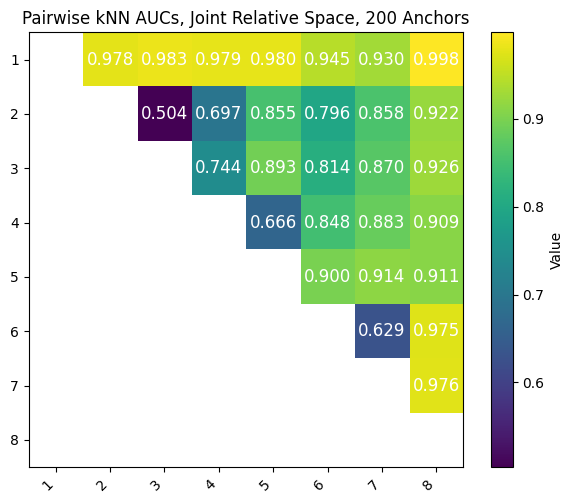

In [8]:
A = classification_aucs.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1,1,1,0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels([f"{i+1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i+1}" for i in range(n)])
ax.set_title("Pairwise kNN AUCs, Joint Relative Space, 200 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i+1, n):
        ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=12, color="w")

plt.tight_layout()
plt.show()

In [ ]:
fisher_ratios = np.zeros((8, 8))

classification_aucs = np.zeros((8, 8))
best_ks = np.zeros((8, 8))

num_events_per_class = 4000

with open('project_path.txt') as f:
    local_project_path = f.read()

for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = local_project_path + f"medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = local_project_path + f"medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = local_project_path + f"medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps_w2 = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=100, seed=42
    )
    
    rel_reps_w2 *= 15
    
    self_matrix_1_file = local_project_path + f"medium_ps/ps_block_{i}_{i}.npy"
    self_matrix_2_file = local_project_path + f"medium_ps/ps_block_{j}_{j}.npy"
    off_diag_matrix_file = local_project_path + f"medium_ps/ps_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps_ps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=400, seed=42
    )
    
    rel_reps = np.concatenate((rel_reps_w2, rel_reps_ps), axis=1)

    dist_mat = pairwise_distance_matrix(rel_reps)

    fisher_ratios[i, j] = comparison_utils.fisher_ratio(
        dist_mat[:num_events_per_class, :num_events_per_class],
        dist_mat[num_events_per_class:, num_events_per_class:],
        dist_mat[:num_events_per_class, num_events_per_class:],
    )

    permutation = np.random.permutation(8000)

    dist_mat = dist_mat[permutation, :][:, permutation]
    labels = labels[permutation]

    train_length = 8000 // 5 * 3
    val_length = 8000 // 5
    test_length = 8000 // 5

    neighbor_list = list(range(1, 400, 4))

    best_auc, best_k, _ = kNN_with_distance_matrix(
        dist_mat, labels, train_length, val_length, test_length, neighbor_list
    )

    classification_aucs[i, j] = best_auc
    best_ks[i, j] = best_k

fisher_ratios = fisher_ratios + fisher_ratios.T
classification_aucs = classification_aucs + classification_aucs.T

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(fisher_ratios, cmap="viridis")  # choose any matplotlib colormap

# axes and labels
ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_xticklabels([f"{i + 1}" for i in range(8)], rotation=45, ha="right")
ax.set_yticklabels([f"{i + 1}" for i in range(8)])
ax.set_title("Pairwise Fisher Ratios, Relative Space, 20 Anchors")

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

fisher_ratio_mean_2 = np.mean(fisher_ratios[fisher_ratios != 0])

# (optional) annotate each cell
for i in range(8):
    for j in range(8):
        ax.text(
            j,
            i,
            f"{fisher_ratios[i, j]:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color="w" if fisher_ratios[i, j] > fisher_ratio_mean_2 else "black",
        )

plt.tight_layout()
plt.show()

In [ ]:
A = classification_aucs.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1,1,1,0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels([f"{i+1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i+1}" for i in range(n)])
ax.set_title("Pairwise kNN AUCs, Relative Space, 20 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i+1, n):
        ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="black")

plt.tight_layout()
plt.show()

In [ ]:
fisher_ratios = np.zeros((8, 8))

classification_aucs = np.zeros((8, 8))
best_ks = np.zeros((8, 8))

num_events_per_class = 4000

with open('project_path.txt') as f:
    local_project_path = f.read()

for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = local_project_path + f"medium_ps/ps_block_{i}_{i}.npy"
    self_matrix_2_file = local_project_path + f"medium_ps/ps_block_{j}_{j}.npy"
    off_diag_matrix_file = local_project_path + f"medium_ps/ps_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=1, seed=42
    )
    dist_mat = pairwise_distance_matrix(rel_reps)

    fisher_ratios[i, j] = comparison_utils.fisher_ratio(
        dist_mat[:num_events_per_class, :num_events_per_class],
        dist_mat[num_events_per_class:, num_events_per_class:],
        dist_mat[:num_events_per_class, num_events_per_class:],
    )

    permutation = np.random.permutation(8000)

    dist_mat = dist_mat[permutation, :][:, permutation]
    labels = labels[permutation]

    train_length = 8000 // 5 * 3
    val_length = 8000 // 5
    test_length = 8000 // 5

    neighbor_list = list(range(1, 400, 4))

    best_auc, best_k, _ = kNN_with_distance_matrix(
        dist_mat, labels, train_length, val_length, test_length, neighbor_list
    )

    classification_aucs[i, j] = best_auc
    best_ks[i, j] = best_k

fisher_ratios = fisher_ratios + fisher_ratios.T
classification_aucs = classification_aucs + classification_aucs.T

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(fisher_ratios, cmap="viridis")  # choose any matplotlib colormap

# axes and labels
ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_xticklabels([f"{i + 1}" for i in range(8)], rotation=45, ha="right")
ax.set_yticklabels([f"{i + 1}" for i in range(8)])
ax.set_title("Pairwise Fisher Ratios, Relative Space, 20 Anchors")

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

fisher_ratio_mean_2 = np.mean(fisher_ratios[fisher_ratios != 0])

# (optional) annotate each cell
for i in range(8):
    for j in range(8):
        ax.text(
            j,
            i,
            f"{fisher_ratios[i, j]:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color="w" if fisher_ratios[i, j] > fisher_ratio_mean_2 else "black",
        )

plt.tight_layout()
plt.show()

In [ ]:
A = classification_aucs.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1,1,1,0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels([f"{i+1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i+1}" for i in range(n)])
ax.set_title("Pairwise kNN AUCs, Relative Space, 2 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i+1, n):
        ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="black")

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# (same matrices M1, M2, M3 defined as before)
M1 = np.array([
    [float('nan'), 0.970, 0.978, 0.980, 0.978, 0.915, 0.898, 0.998],
    [float('nan'), float('nan'), 0.514, 0.500, 0.518, 0.799, 0.852, 0.895],
    [float('nan'), float('nan'), float('nan'), 0.516, 0.552, 0.812, 0.865, 0.877],
    [float('nan'), float('nan'), float('nan'), float('nan'), 0.499, 0.812, 0.870, 0.896],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.807, 0.860, 0.899],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.618, 0.971],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.975],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan')],
])

M2 = np.array([
    [float('nan'), 0.976, 0.979, 0.975, 0.976, 0.926, 0.901, 0.998],
    [float('nan'), float('nan'), 0.532, 0.524, 0.634, 0.798, 0.851, 0.894],
    [float('nan'), float('nan'), float('nan'), 0.522, 0.624, 0.813, 0.868, 0.883],
    [float('nan'), float('nan'), float('nan'), float('nan'), 0.578, 0.811, 0.870, 0.896],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.811, 0.866, 0.901],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.616, 0.972],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.975],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan')],
])

M3 = np.array([
    [float('nan'), 0.976, 0.978, 0.977, 0.977, 0.927, 0.905, 0.997],
    [float('nan'), float('nan'), 0.536, 0.523, 0.635, 0.797, 0.853, 0.892],
    [float('nan'), float('nan'), float('nan'), 0.520, 0.648, 0.812, 0.867, 0.884],
    [float('nan'), float('nan'), float('nan'), float('nan'), 0.580, 0.811, 0.870, 0.896],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.818, 0.865, 0.900],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.611, 0.972],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), 0.974],
    [float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan'), float('nan')],
])

matrices = [M1, M2, M3]
titles = [
    "Pairwise kNN AUCs, Relative Space, 2 Anchors",
    "Pairwise kNN AUCs, Relative Space, 20 Anchors",
    "Pairwise kNN AUCs, Relative Space, 200 Anchors",
]

# Mask diagonal + lower triangle
masked = [
    np.ma.masked_where(~np.triu(np.ones_like(M), k=1).astype(bool), M) for M in matrices
]

# Compute global vmin and vmax excluding zeros
all_values = np.concatenate([M[np.triu_indices_from(M, k=1)] for M in matrices])
vmin, vmax = all_values.min(), all_values.max()

fig, axes = plt.subplots(1, 3, figsize=(30, 10), constrained_layout=True)
cmap = plt.cm.viridis

for ax, mat, title in zip(axes, masked, titles):
    im = ax.imshow(mat, vmin=vmin, vmax=vmax, cmap=cmap)
    # optional: annotate
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if i < j:
                ax.text(
                    j,
                    i,
                    f"{mat.data[i, j]:.3f}",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=22,
                )
    ax.set_title(title)
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticklabels(range(1, 9))
    ax.set_yticklabels(range(1, 9))

# Shared colorbar
cbar = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.02, pad=0.04)
cbar.set_label("Value")
cbar.set_ticks(np.linspace(vmin, vmax, 6))

plt.show()